<a href="https://colab.research.google.com/github/Chiragdas21/Chiragdas21/blob/main/IPCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q ultralytics
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
%pip install -q ultralytics
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
results = model.train(data="african-wildlife.yaml", epochs=30, imgsz=640, batch=16)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Displaying runs/detect/train/results.png:


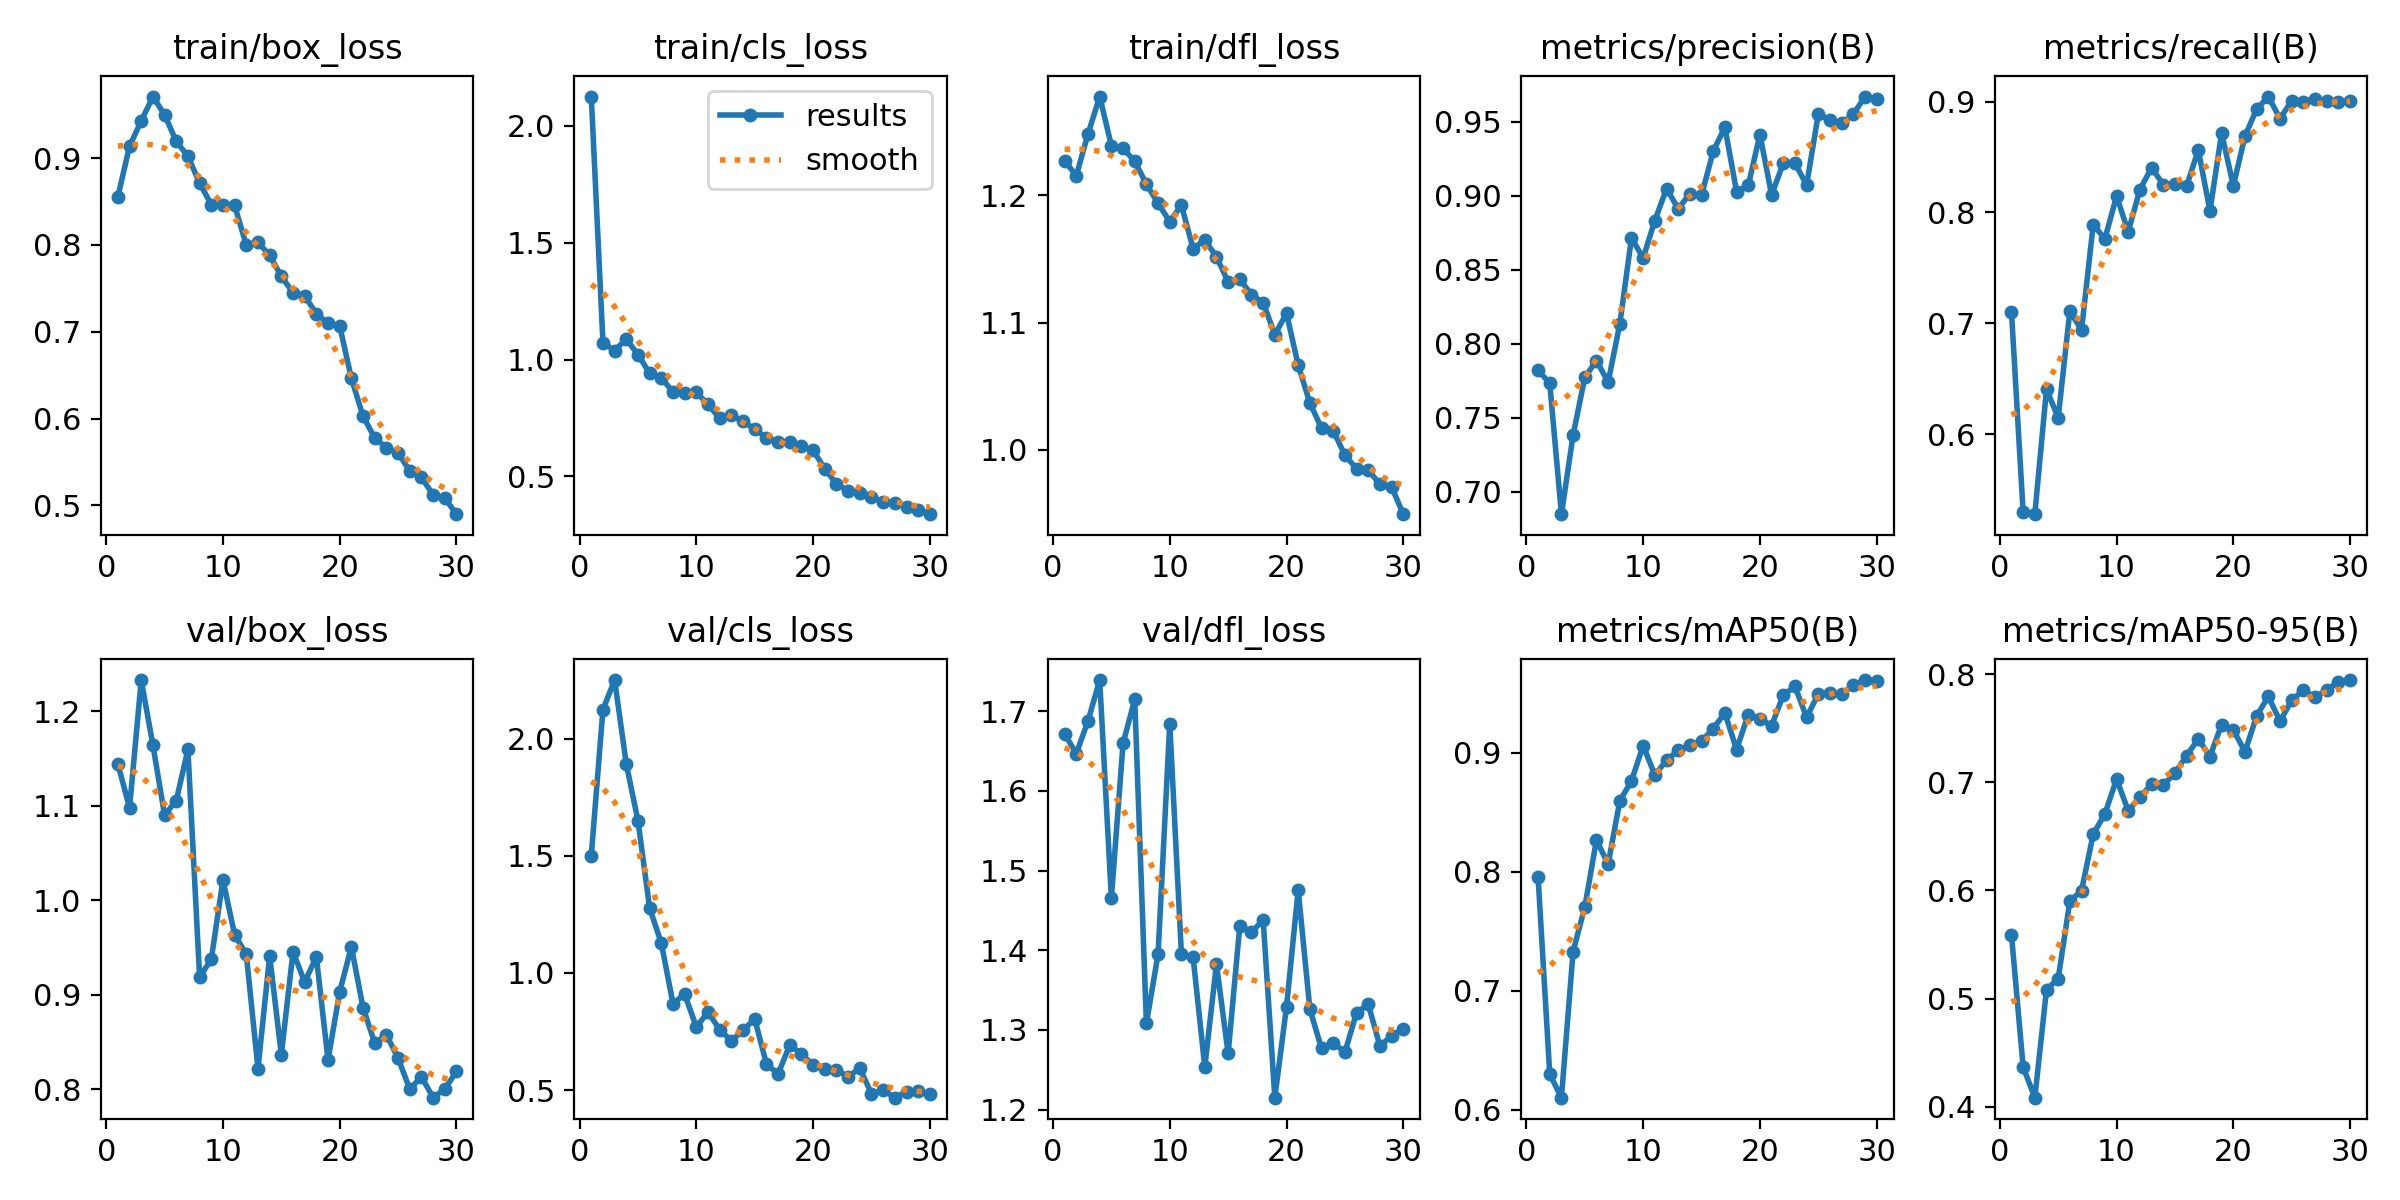

Displaying runs/detect/train/confusion_matrix.png:


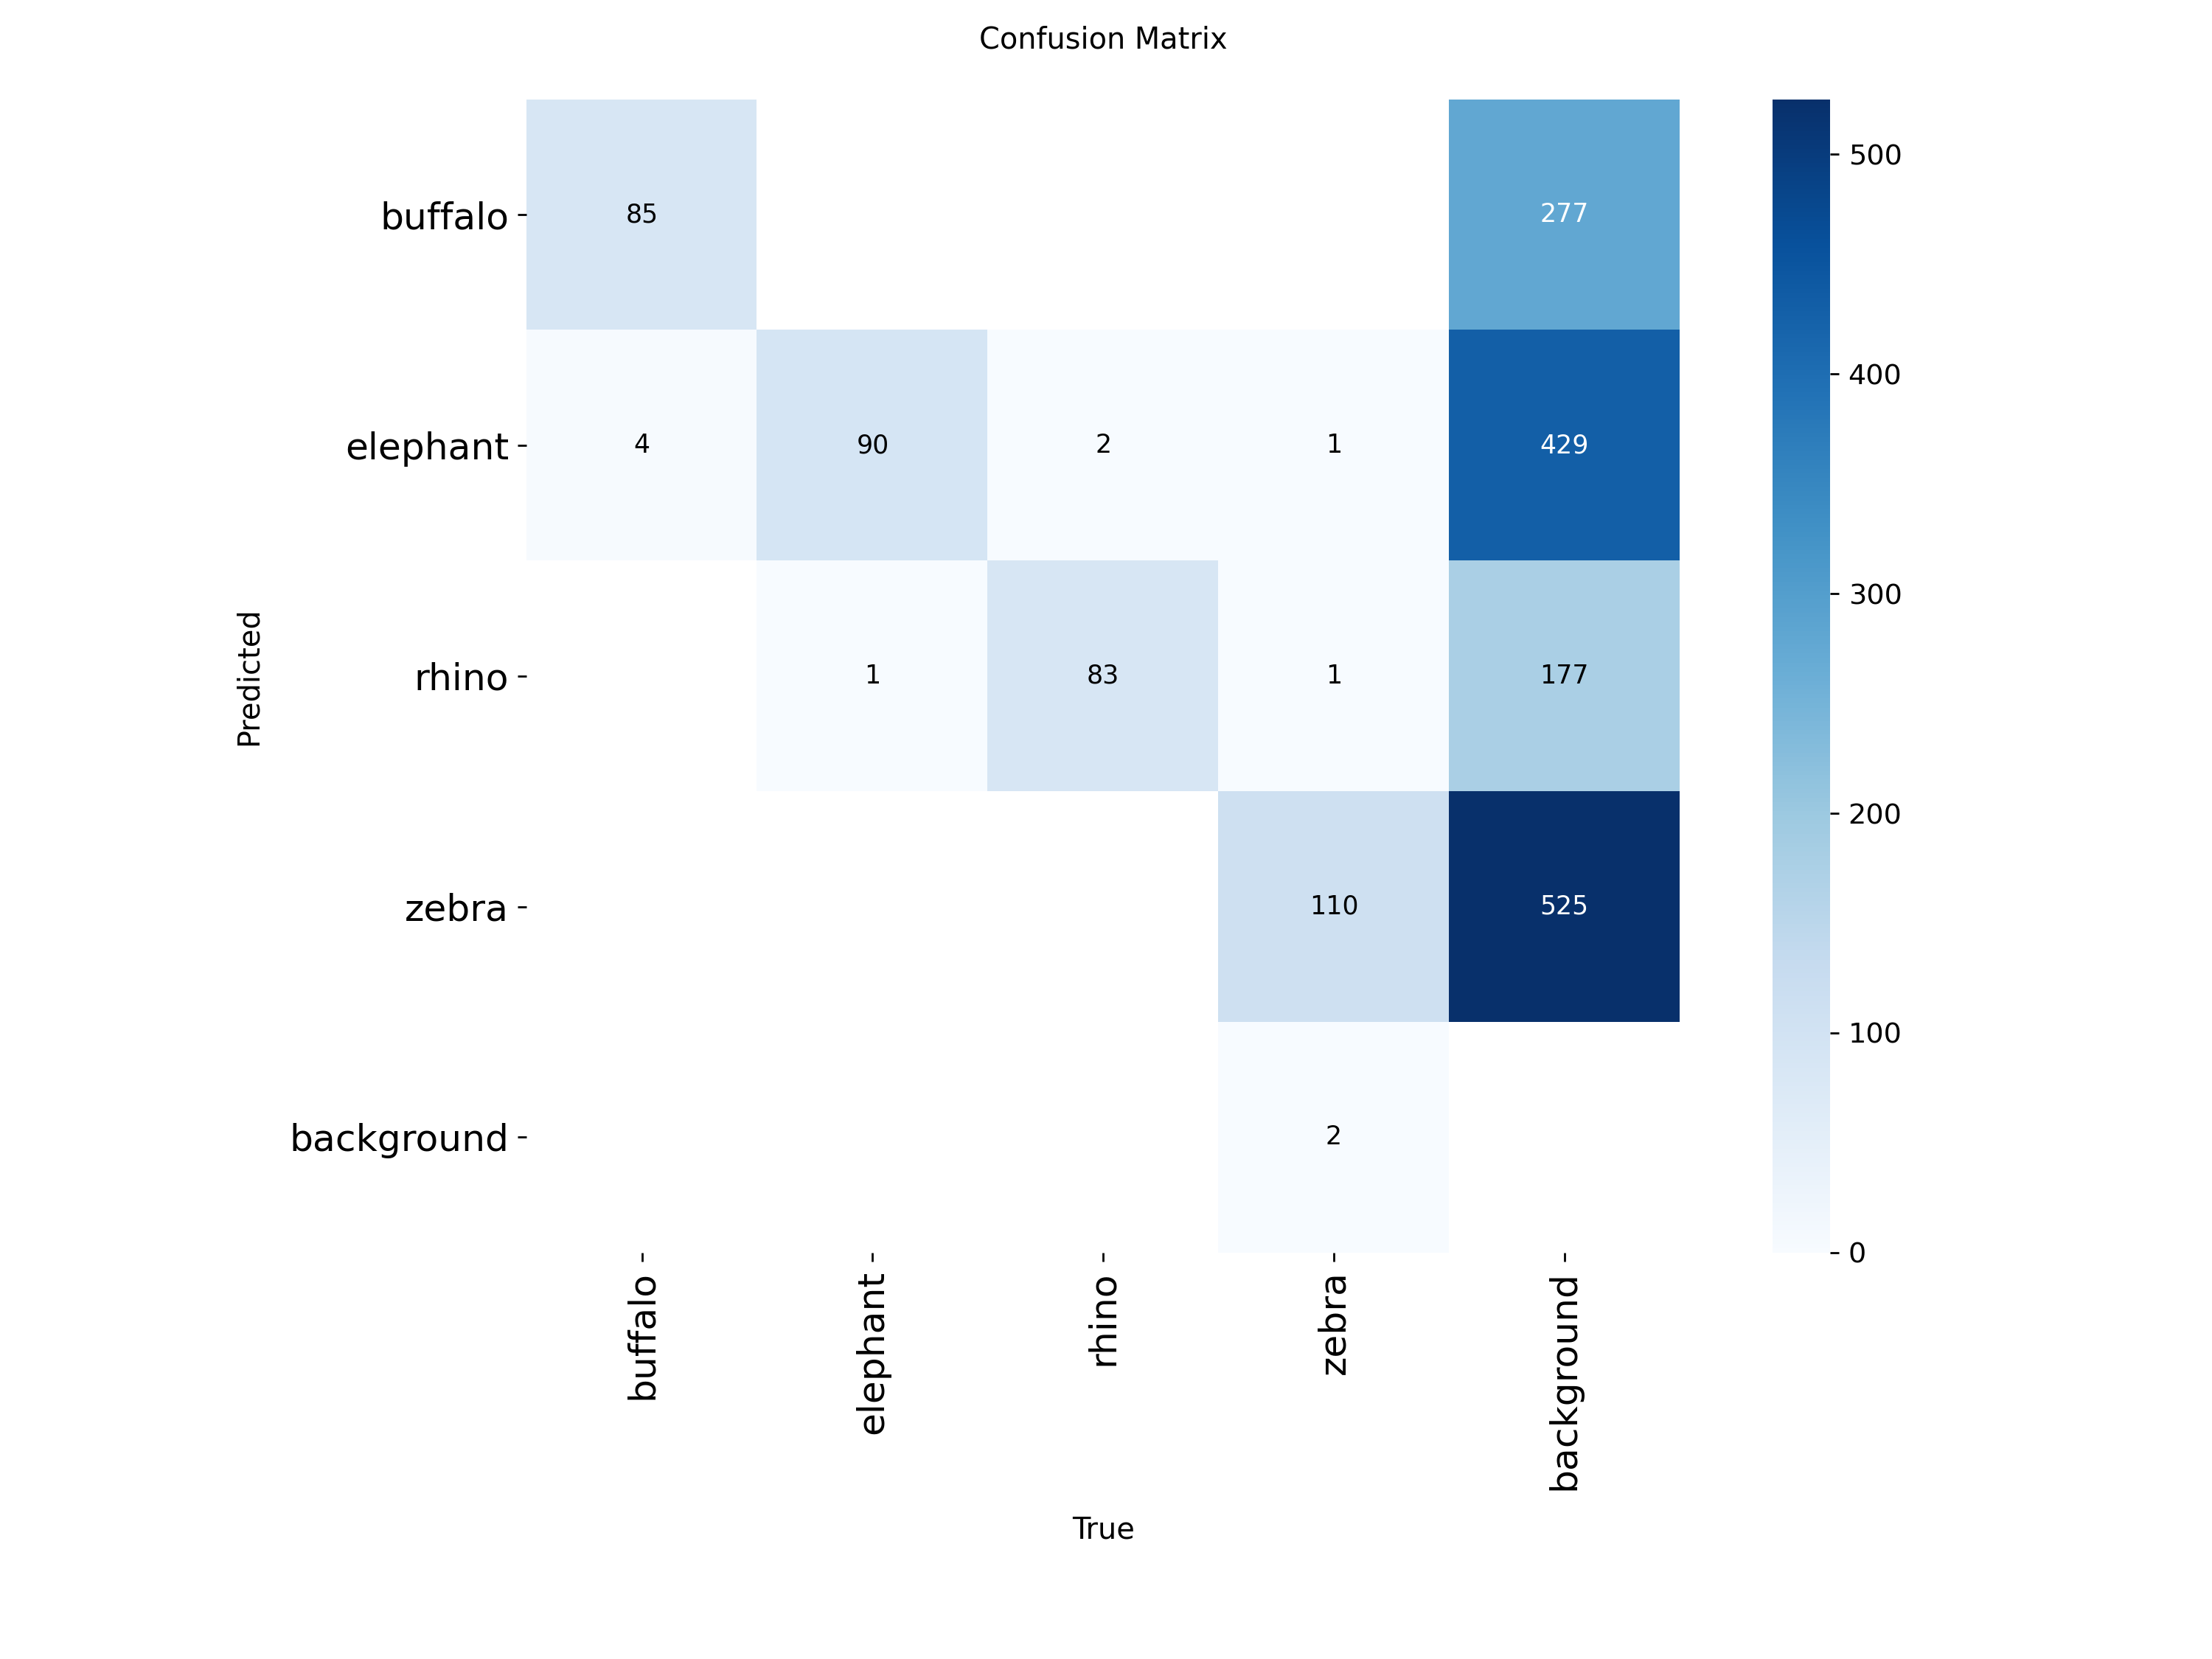

Skipping runs/detect/train/PR_curve.png (file not found)
Skipping runs/detect/train/P_curve.png (file not found)
Skipping runs/detect/train/R_curve.png (file not found)
Skipping runs/detect/train/F1_curve.png (file not found)
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1284.0±955.5 MB/s, size: 99.8 KB)
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 49.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.5it/s 6.1s
                   all        225        379      0.962      0.903       0.96      0.792
               buffalo         62         89      0.967       0.91      0.971      0.818
              elephant         53         91      0.951      0.861      0

In [6]:
import os
from IPython.display import Image, display
from ultralytics import YOLO

# Safely display validation images that exist
plots = [
    "runs/detect/train/results.png",
    "runs/detect/train/confusion_matrix.png",
    "runs/detect/train/PR_curve.png",
    "runs/detect/train/P_curve.png",
    "runs/detect/train/R_curve.png",
    "runs/detect/train/F1_curve.png"
]

for plot in plots:
    if os.path.exists(plot):
        print(f"Displaying {plot}:")
        display(Image(plot))
    else:
        print(f"Skipping {plot} (file not found)")

best = YOLO("runs/detect/train/weights/best.pt")
m = best.val()
print("\n--- Validation Metrics ---")
print("Precision:", m.box.mp)
print("Recall:", m.box.mr)
print("mAP@0.5:", m.box.map50)
print("mAP@0.5:0.95:", m.box.map)


image 1/225 /content/datasets/african-wildlife/images/val/1 (1).jpg: 352x640 1 buffalo, 10.0ms
image 2/225 /content/datasets/african-wildlife/images/val/1 (102).jpg: 480x640 1 buffalo, 52.8ms
image 3/225 /content/datasets/african-wildlife/images/val/1 (111).jpg: 480x640 1 buffalo, 30.0ms
image 4/225 /content/datasets/african-wildlife/images/val/1 (120).jpg: 448x640 2 buffalos, 61.6ms
image 5/225 /content/datasets/african-wildlife/images/val/1 (122).jpg: 448x640 1 buffalo, 39.5ms
image 6/225 /content/datasets/african-wildlife/images/val/1 (127).jpg: 448x640 1 buffalo, 39.8ms
image 7/225 /content/datasets/african-wildlife/images/val/1 (136).jpg: 448x640 1 buffalo, 50.5ms
image 8/225 /content/datasets/african-wildlife/images/val/1 (138).jpg: 448x640 1 buffalo, 59.4ms
image 9/225 /content/datasets/african-wildlife/images/val/1 (145).jpg: 448x640 1 buffalo, 22.9ms
image 10/225 /content/datasets/african-wildlife/images/val/1 (149).jpg: 480x640 1 buffalo, 32.4ms
image 11/225 /content/dataset

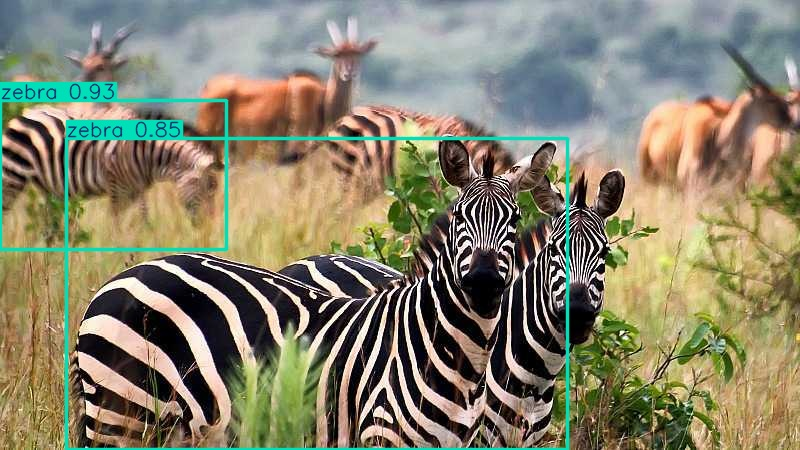

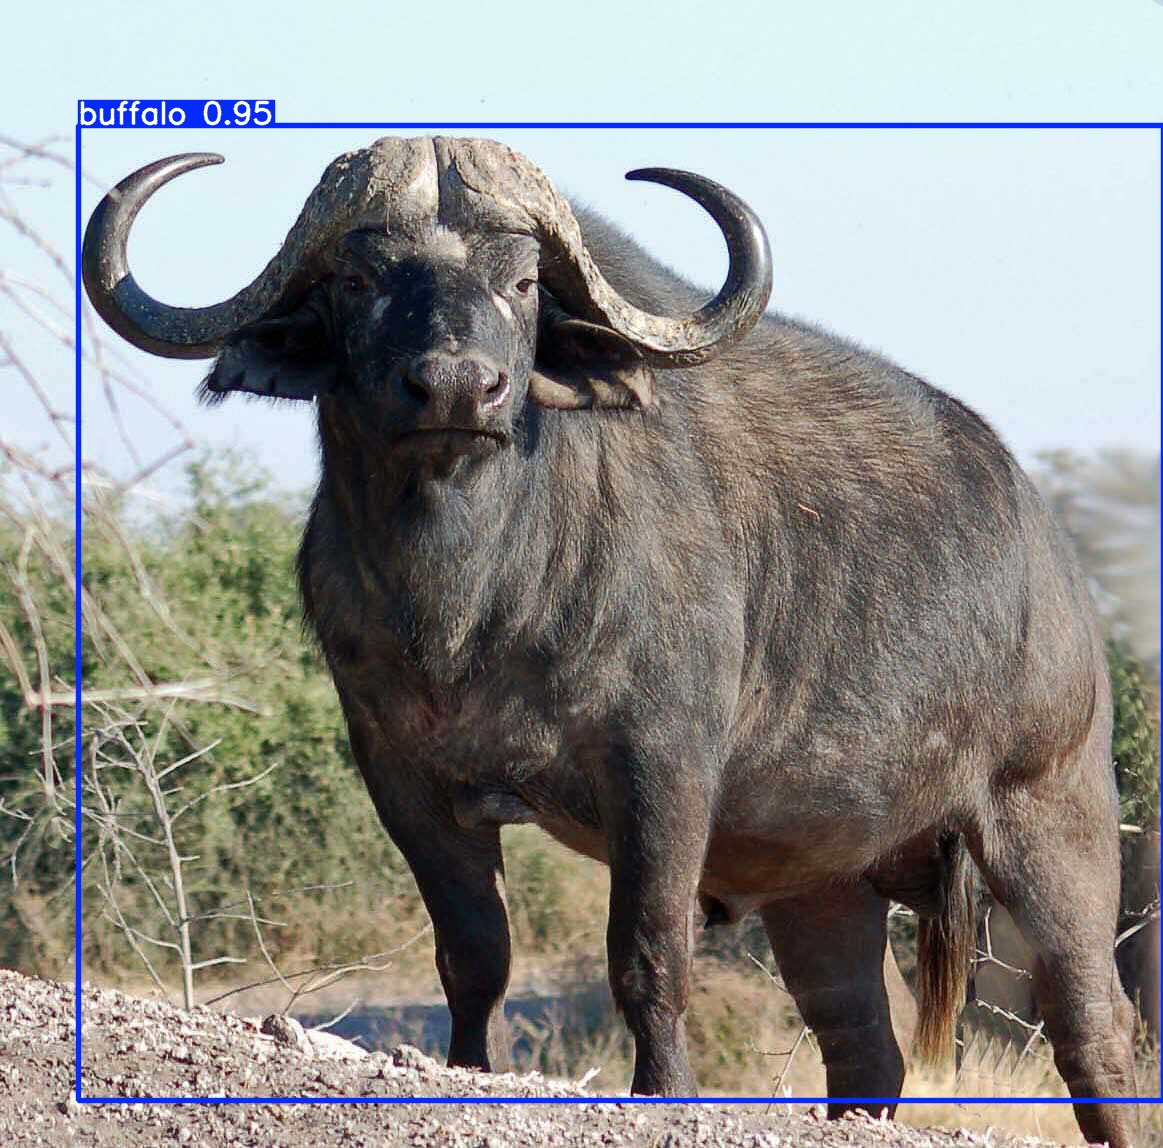

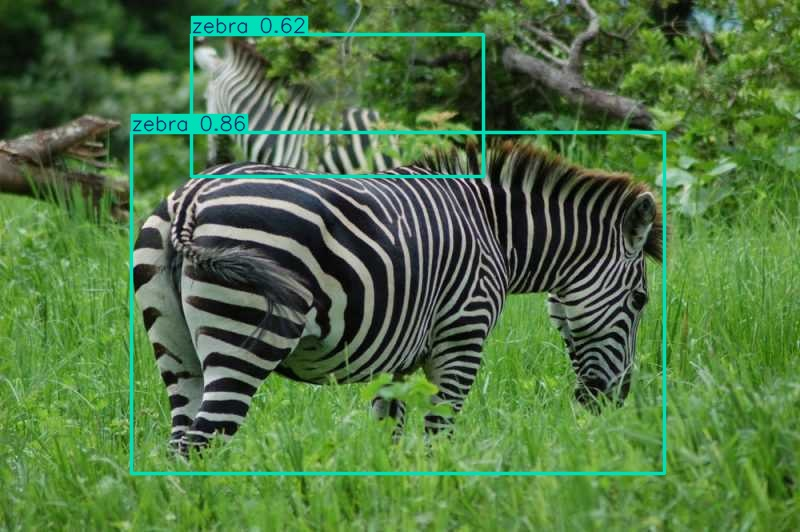

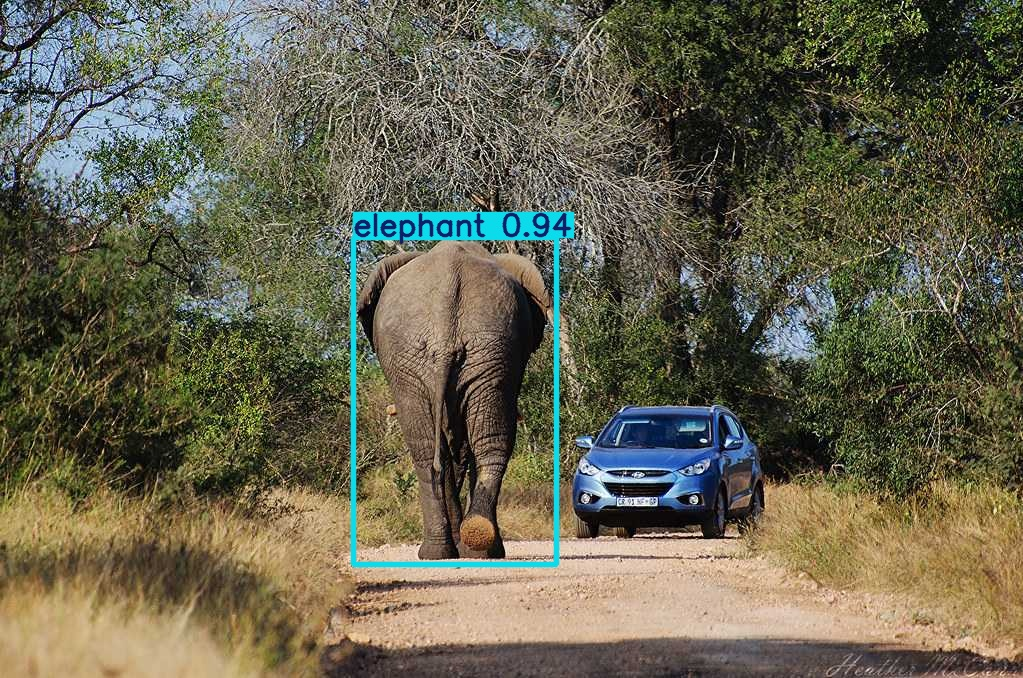

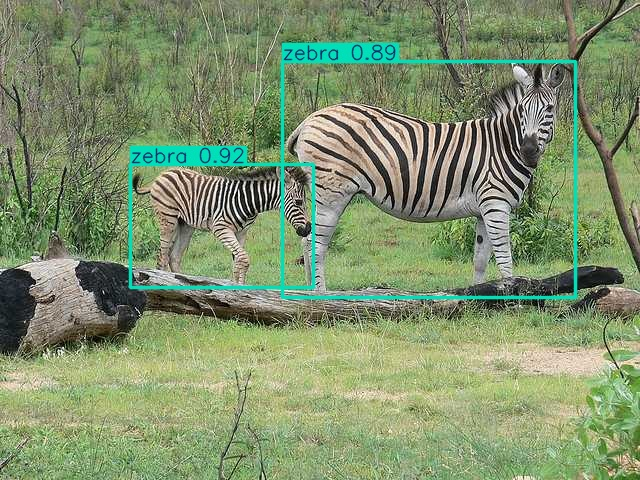

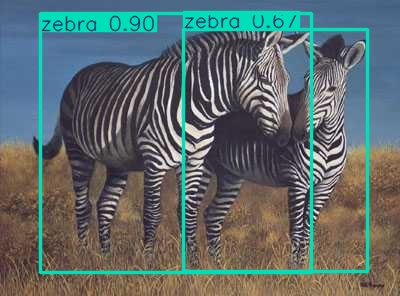

In [7]:
import glob
from IPython.display import Image, display

best.predict("/content/datasets/african-wildlife/images/val", save=True, conf=0.4, max_det=20)
for f in glob.glob("runs/detect/predict/*.jpg")[:6]:
    display(Image(f))

In [11]:
import glob, os, random, shutil, yaml
from ultralytics import YOLO

!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip -O coco128.zip
!unzip -q -o coco128.zip -d /content/datasets

# drop COCO images with cow/elephant/zebra (they look like your classes)
BAD = {19, 20, 22}
keep = []
for lf in glob.glob("/content/datasets/coco128/labels/train2017/*.txt"):
    cls = {int(l.split()[0]) for l in open(lf) if l.strip()}
    if not cls & BAD:
        keep.append(os.path.basename(lf)[:-4])
random.seed(0); random.shuffle(keep)
k = int(0.7 * len(keep))
neg, ood = keep[:k], keep[k:]      # neg = train negatives, ood = held-out test
print(len(neg), "negatives,", len(ood), "OOD test images")

# copy dataset, add negatives with EMPTY label files
!ls /content/datasets/african-wildlife
shutil.copytree("/content/datasets/african-wildlife", "/content/wildlife_neg", dirs_exist_ok=True)
for n_ in neg:
    src_img = f"/content/datasets/coco128/images/train2017/{n_}.jpg"
    if os.path.exists(src_img):
        shutil.copy(src_img, f"/content/wildlife_neg/images/train/neg_{n_}.jpg")
        open(f"/content/wildlife_neg/labels/train/neg_{n_}.txt", "w").close()

names = YOLO("runs/detect/train/weights/best.pt").names
yaml.dump({"path": "/content/wildlife_neg", "train": "images/train",
           "val": "images/val", "test": "images/test", "names": names},
          open("/content/wildlife_neg/data.yaml", "w"))

85 negatives, 37 OOD test images
african-wildlife.yaml  images  labels  LICENSE.txt


In [12]:
YOLO("yolov8n.pt").train(data="/content/wildlife_neg/data.yaml", epochs=30,
                         imgsz=640, batch=16, name="yolov8n_neg")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/wildlife_neg/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_neg, nbs=64, nms=None, opset=None, optimize=False

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e49ab5a2ac0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [13]:
import pandas as pd
import os
Y = "/content/wildlife_neg/data.yaml"
runs = {"YOLOv8n": "train", "YOLOv8s": "yolov8s_run", "YOLOv8n+neg": "yolov8n_neg"}

# Filter out files that do not actually exist in coco128
ood_files = [
    f"/content/datasets/coco128/images/train2017/{x}.jpg"
    for x in ood
    if os.path.exists(f"/content/datasets/coco128/images/train2017/{x}.jpg")
]

def ood_fp(m, conf):
    if not ood_files:
        return 0.0
    hits = sum(len(r.boxes) > 0 for r in m.predict(ood_files, conf=conf, verbose=False, stream=True))
    return round(100 * hits / len(ood_files), 1)

loaded, rows, cls_rows = {}, [], []
for name, d in runs.items():
    best_path = f"runs/detect/{d}/weights/best.pt"
    if not os.path.exists(best_path):
        print(f"Skipping {name} as weight file {best_path} does not exist.")
        continue
    m = YOLO(best_path); loaded[name] = m
    r = m.val(data=Y, verbose=False)
    rows.append({"Model": name, "Params(M)": round(sum(p.numel() for p in m.model.parameters())/1e6, 1),
                 "Precision": round(r.box.mp, 3), "Recall": round(r.box.mr, 3),
                 "mAP50": round(r.box.map50, 3), "mAP50-95": round(r.box.map, 3),
                 "ms/img": round(r.speed["inference"], 1),
                 "OOD false alarm % @0.4": ood_fp(m, 0.4)})
    for i, c in enumerate(r.box.ap_class_index):
        cls_rows.append({"Model": name, "Class": r.names[c], "AP50": round(r.box.ap50[i], 3)})

if rows:
    table = pd.DataFrame(rows); display(table)
if cls_rows:
    per_class = pd.DataFrame(cls_rows).pivot(index="Class", columns="Model", values="AP50"); display(per_class)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1718.7±1358.6 MB/s, size: 99.8 KB)
val: Scanning /content/wildlife_neg/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 49.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.5it/s 3.3s
                   all        225        379      0.962      0.903       0.96      0.792
Speed: 1.4ms preprocess, 3.6ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-2
Skipping YOLOv8s as weight file runs/detect/yolov8s_run/weights/best.pt does not exist.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access

,Model,Params(M),Precision,Recall,mAP50,mAP50-95,ms/img,OOD false alarm % @0.4
0,YOLOv8n,3.1,0.962,0.903,0.96,0.792,3.6,67.6
1,YOLOv8n+neg,3.1,0.937,0.910,0.95,0.803,3.0,5.4


Model,YOLOv8n,YOLOv8n+neg
Class,,
buffalo,0.971,0.948
elephant,0.944,0.943
rhino,0.974,0.961
zebra,0.952,0.950


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.2 ms, read: 1428.0±344.2 MB/s, size: 57.6 KB)
val: Scanning /content/wildlife_neg/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 39.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.7it/s 3.2s
                   all        225        379      0.937       0.91      0.914      0.775
Speed: 1.5ms preprocess, 3.2ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val-4
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1156.1±893.8 MB/s, size: 24.2 KB)
val: Scanning /content/wild

,conf,Precision,Recall,OOD false alarm %
0,0.25,0.937,0.910,8.1
1,0.40,0.933,0.912,5.4
2,0.50,0.943,0.893,0.0
3,0.60,0.952,0.859,0.0
4,0.70,0.962,0.835,0.0
5,0.80,0.976,0.781,0.0


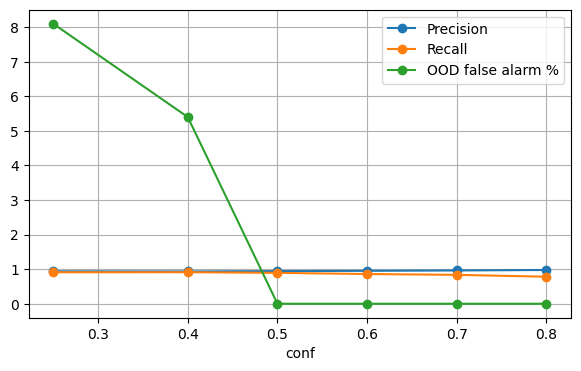

In [14]:
import matplotlib.pyplot as plt
mm = loaded["YOLOv8n+neg"]; sweep = []
for c in [0.25, 0.4, 0.5, 0.6, 0.7, 0.8]:
    r = mm.val(data=Y, conf=c, verbose=False)
    sweep.append({"conf": c, "Precision": round(r.box.mp, 3), "Recall": round(r.box.mr, 3),
                  "OOD false alarm %": ood_fp(mm, c)})
sw = pd.DataFrame(sweep); display(sw)
sw.set_index("conf").plot(marker="o", figsize=(7, 4)); plt.grid(); plt.show()

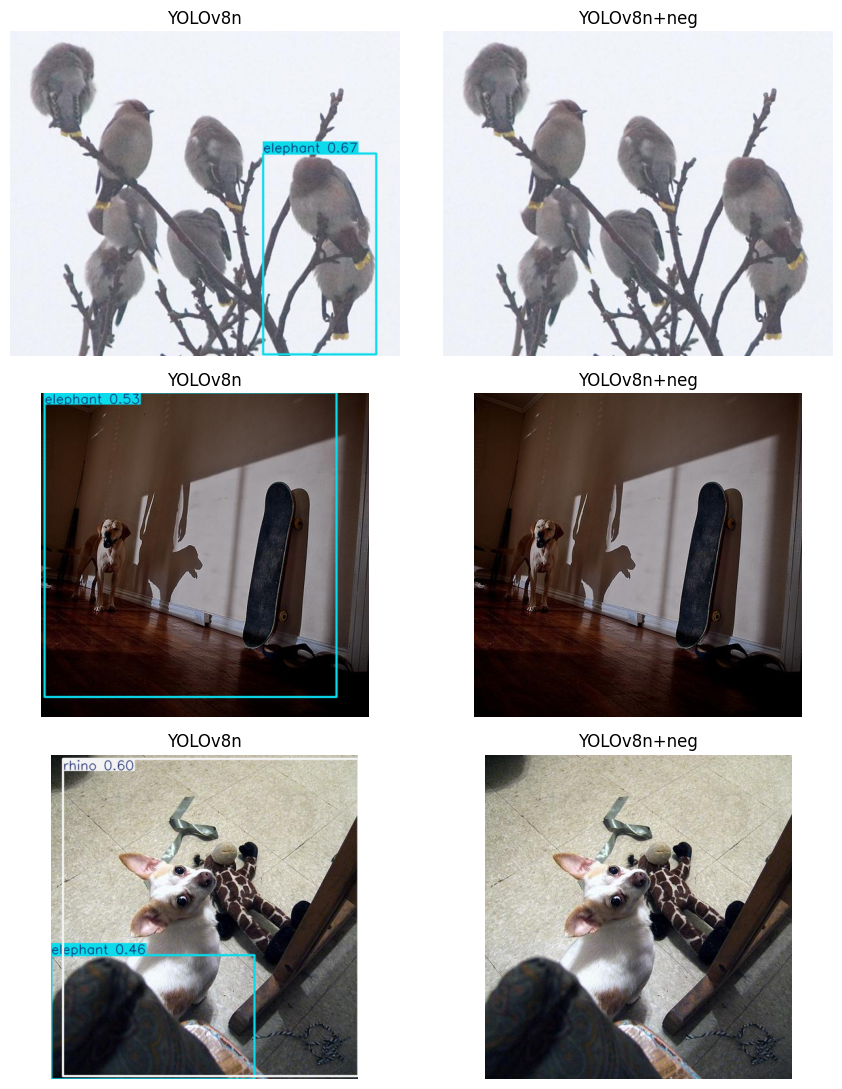

In [15]:
import cv2
fig, ax = plt.subplots(3, 2, figsize=(9, 11))
for i, f in enumerate(ood_files[:3]):
    for j, name in enumerate(["YOLOv8n", "YOLOv8n+neg"]):
        ax[i][j].imshow(cv2.cvtColor(loaded[name].predict(f, conf=0.4, verbose=False)[0].plot(), cv2.COLOR_BGR2RGB))
        ax[i][j].set_title(name); ax[i][j].axis("off")
plt.tight_layout(); plt.show()

YOLOv8n


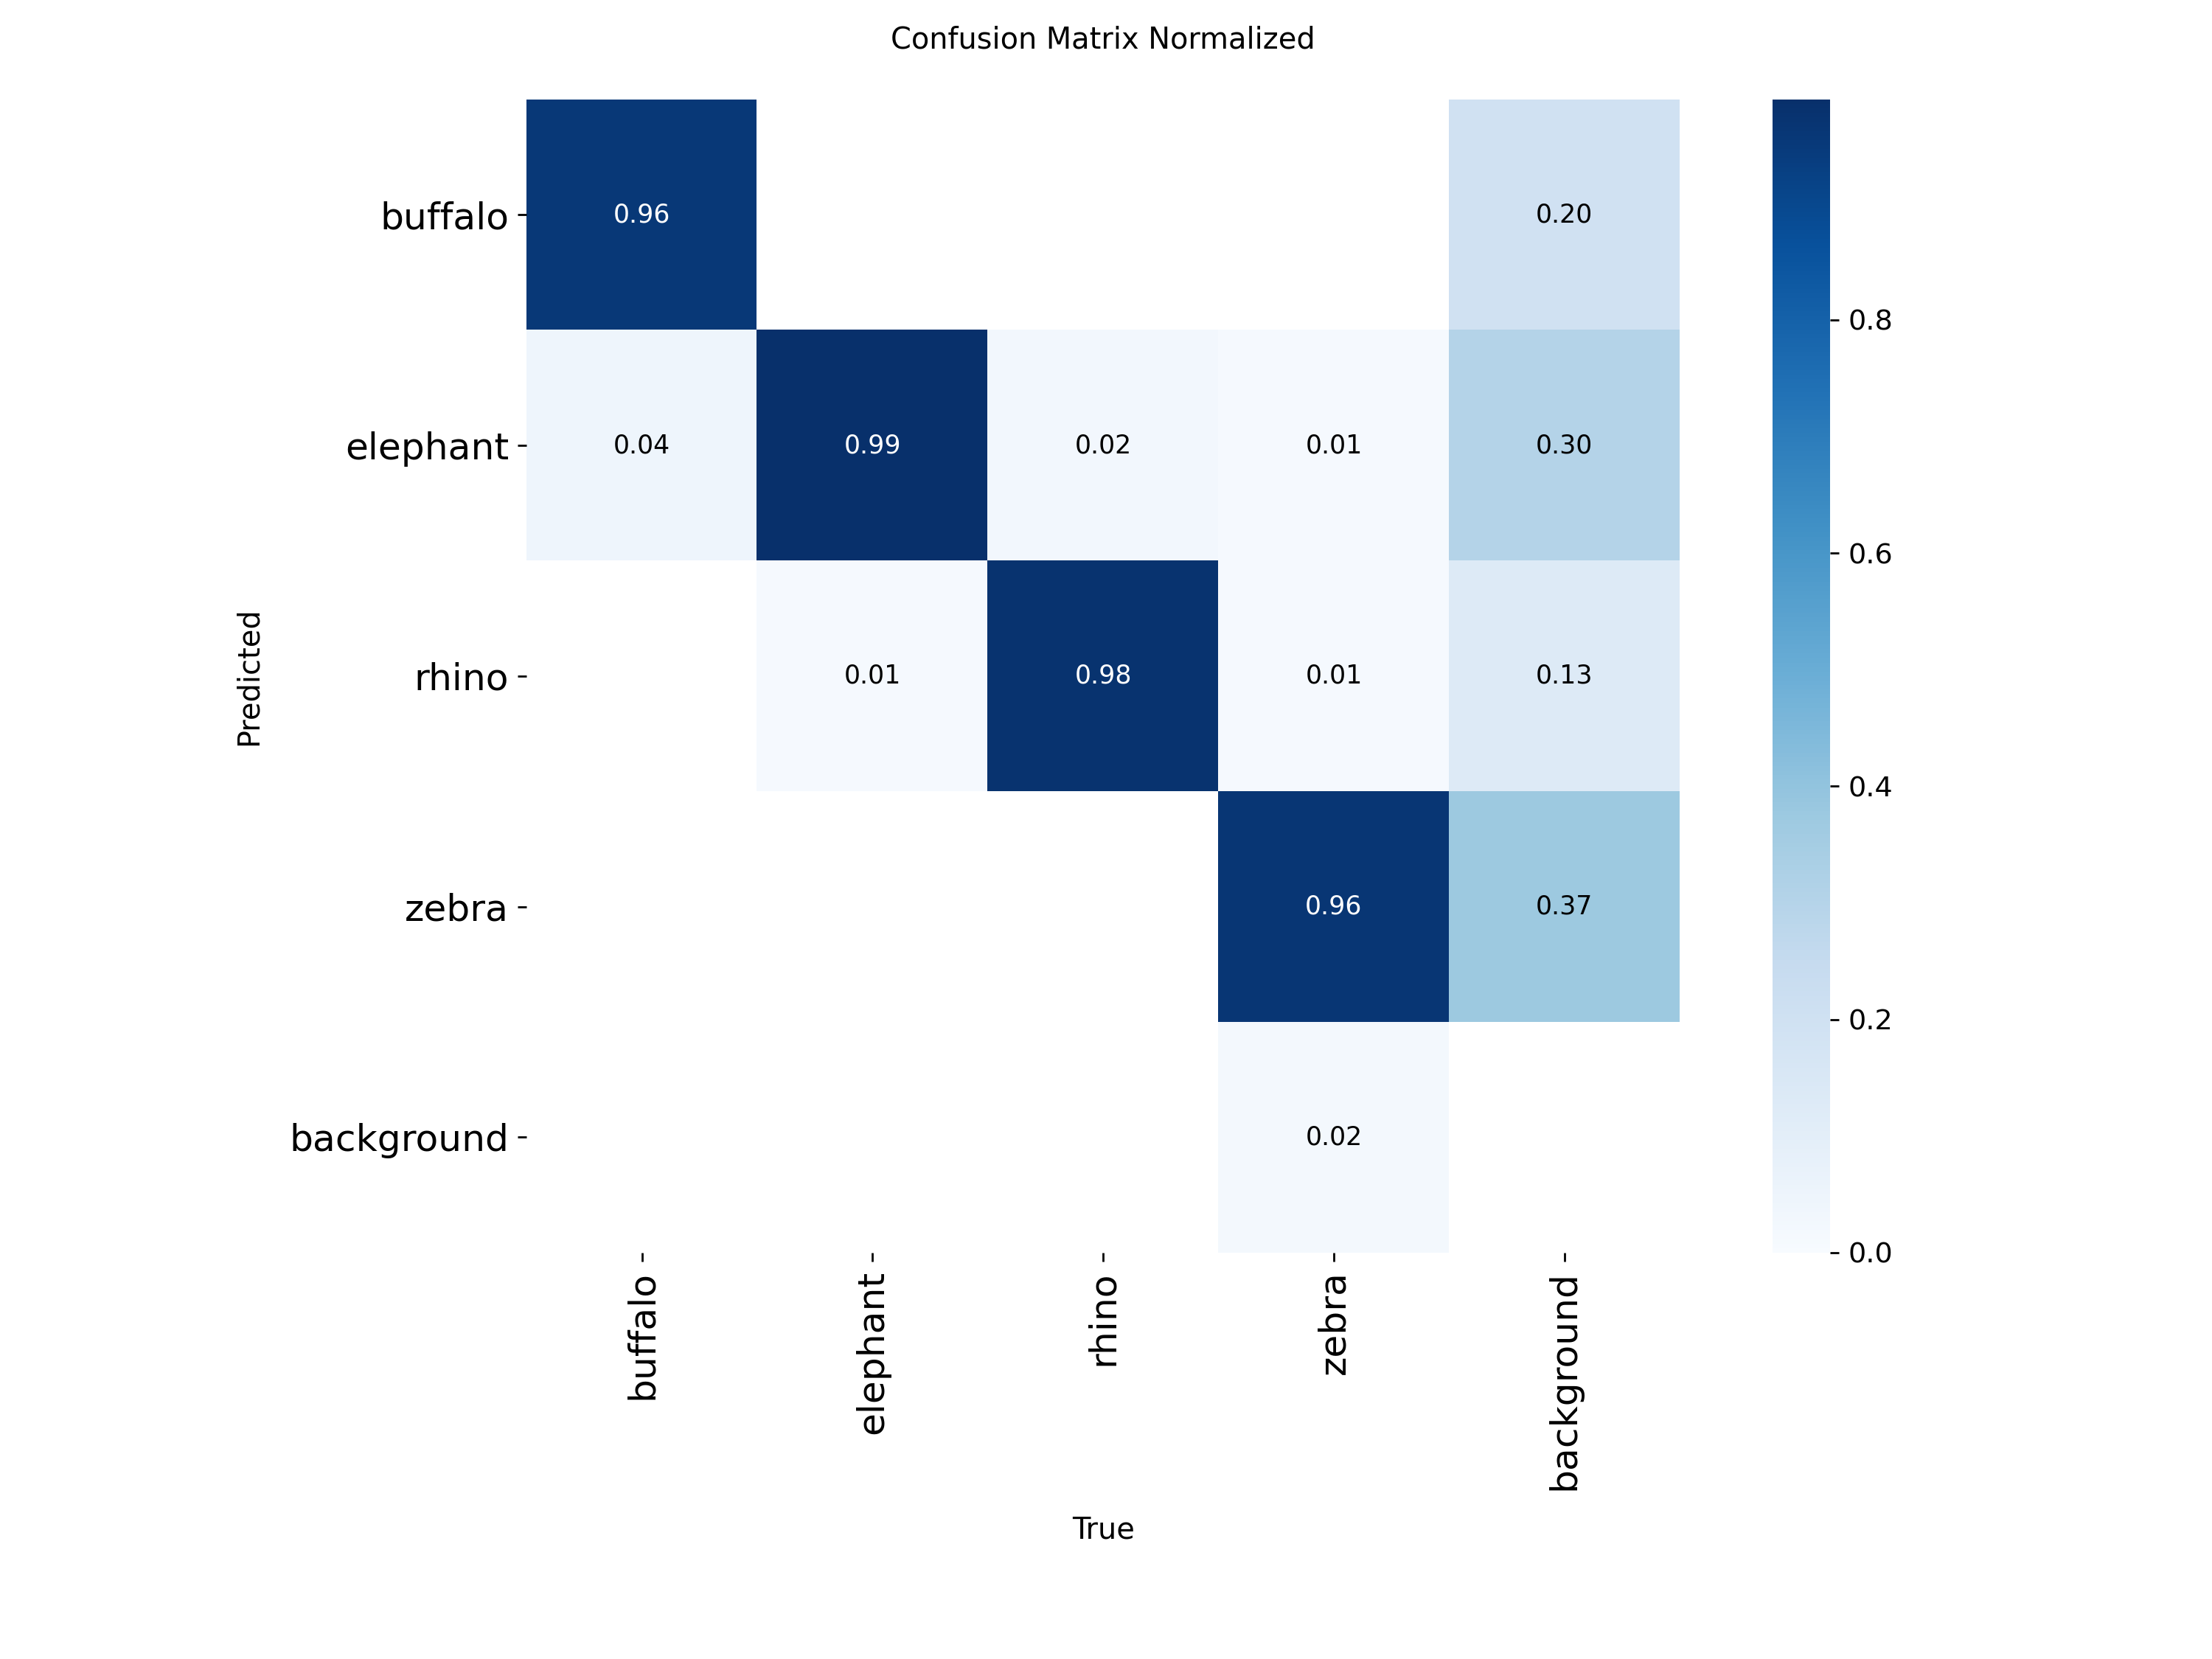

  Skipping PR_curve.png (file does not exist in train)
  Skipping F1_curve.png (file does not exist in train)
YOLOv8s: Normalized confusion matrix not found.
  Skipping results.png (file does not exist in yolov8s_run)
  Skipping confusion_matrix_normalized.png (file does not exist in yolov8s_run)
  Skipping PR_curve.png (file does not exist in yolov8s_run)
  Skipping F1_curve.png (file does not exist in yolov8s_run)
YOLOv8n+neg


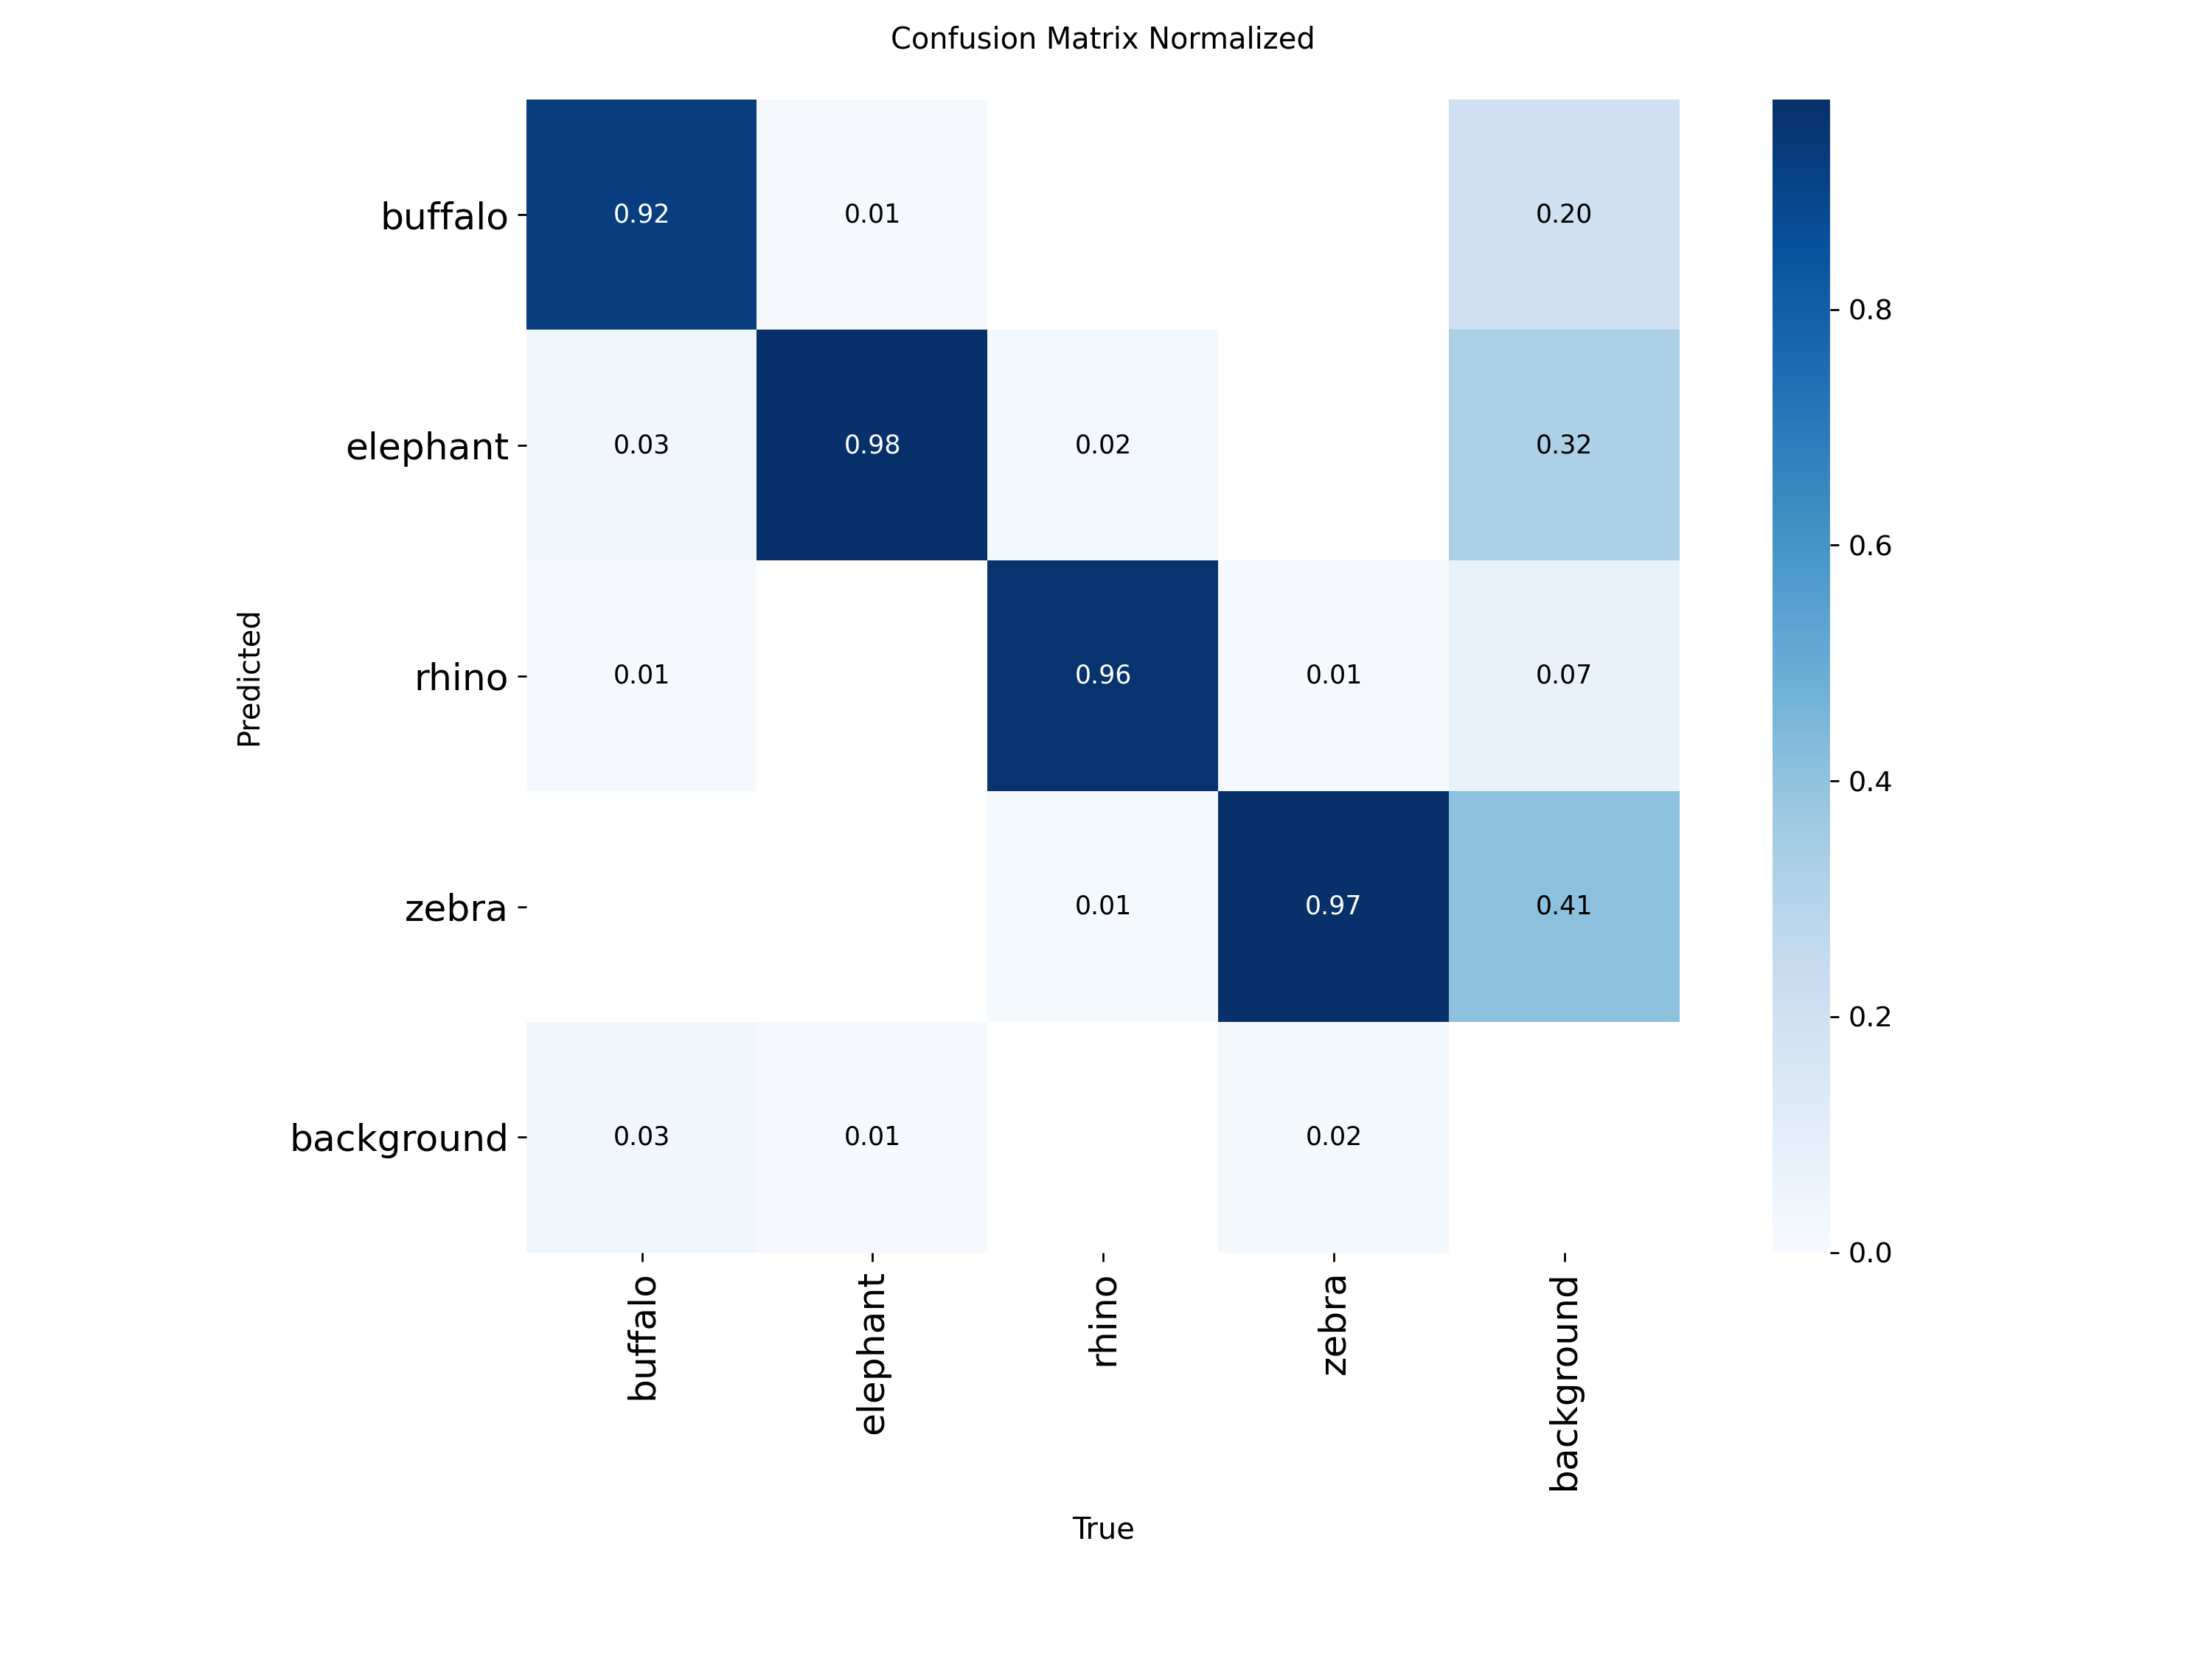

  Skipping PR_curve.png (file does not exist in yolov8n_neg)
  Skipping F1_curve.png (file does not exist in yolov8n_neg)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from IPython.display import Image, display
import os
import shutil

os.makedirs("paper_figs", exist_ok=True)
for name, d in runs.items():
    matrix_path = f"runs/detect/{d}/confusion_matrix_normalized.png"
    if os.path.exists(matrix_path):
        print(name)
        display(Image(matrix_path))
    else:
        print(f"{name}: Normalized confusion matrix not found.")

    for f in ["results.png", "confusion_matrix_normalized.png", "PR_curve.png", "F1_curve.png"]:
        src_path = f"runs/detect/{d}/{f}"
        if os.path.exists(src_path):
            shutil.copy(src_path, f"paper_figs/{name.replace('+','_')}_{f}")
        else:
            print(f"  Skipping {f} (file does not exist in {d})")

table.to_csv("paper_figs/comparison.csv", index=False)
open("paper_figs/comparison.tex", "w").write(table.to_latex(index=False))
per_class.to_csv("paper_figs/per_class_ap.csv")
sw.to_csv("paper_figs/conf_sweep.csv", index=False)

!zip -qr paper_figs.zip paper_figs
from google.colab import files
try:
    files.download("paper_figs.zip")
except Exception as e:
    print("File download requested. If automatic download does not start, you can download paper_figs.zip manually from the file explorer.")

In [17]:
import os, pandas as pd
rows = []
for name, d in runs.items():
    w = f"runs/detect/{d}/weights/best.pt"
    if not os.path.exists(w):
        print(f"Skipping {name} (weight file {w} does not exist)")
        continue
    m = YOLO(w)
    r = m.val(data=Y, verbose=False)
    p, rc = r.box.mp, r.box.mr
    total_ms = r.speed["preprocess"] + r.speed["inference"] + r.speed["postprocess"]
    rows.append({
        "Model": name,
        "Precision": round(p, 3),
        "Recall": round(rc, 3),
        "F1-score": round(2 * p * rc / (p + rc + 1e-9), 3),
        "mAP@0.5": round(r.box.map50, 3),
        "mAP@0.5:0.95": round(r.box.map, 3),
        "Inference (ms/img)": round(r.speed["inference"], 1),
        "Total (ms/img)": round(total_ms, 1),
        "FPS": round(1000 / total_ms, 1),
        "Model size (MB)": round(os.path.getsize(w) / 1e6, 1),
    })
metrics = pd.DataFrame(rows)
display(metrics)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1111.0±639.3 MB/s, size: 67.8 KB)
val: Scanning /content/wildlife_neg/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 55.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.9it/s 3.8s
                   all        225        379      0.962      0.903       0.96      0.792
Speed: 1.9ms preprocess, 3.8ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val-10
Skipping YOLOv8s (weight file runs/detect/yolov8s_run/weights/best.pt does not exist)
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅

,Model,Precision,Recall,F1-score,mAP@0.5,mAP@0.5:0.95,Inference (ms/img),Total (ms/img),FPS,Model size (MB)
0,YOLOv8n,0.962,0.903,0.931,0.96,0.792,3.8,7.8,128.5,6.5
1,YOLOv8n+neg,0.937,0.910,0.923,0.95,0.803,3.8,7.3,137.0,6.5


In [18]:
import time
import os
import glob

t = time.time()
# Perform inference using the fine-tuned 'best' model
results = best.predict("video.mp4", save=True, conf=0.5, project="/content/demo", name="out", exist_ok=True)
print("Processed in", round(time.time() - t, 1), "s")

# Find the exact saved video file using absolute paths
saved_videos = glob.glob("/content/demo/out/*.avi") + glob.glob("/content/demo/out/*.mp4")
if saved_videos:
    input_video = saved_videos[0]
    print(f"Found output video at: {input_video}. Converting format...")
    # Convert to web-friendly H.264 mp4 format
    !ffmpeg -y -i "{input_video}" /content/demo/out/video_out.mp4 -vcodec libx264 -f mp4 -loglevel quiet

    if os.path.exists("/content/demo/out/video_out.mp4"):
        from IPython.display import HTML
        from base64 import b64encode
        v = b64encode(open("/content/demo/out/video_out.mp4", "rb").read()).decode()
        display(HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{v}"></video>'))
    else:
        print("Error: ffmpeg conversion failed to generate video_out.mp4")
else:
    print("Error: YOLO did not save any output video in /content/demo/out/")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/291) /content/video.mp4: 352x640 (no detections), 22.4ms
video 1/1 (frame 2/291) /content/video.mp4: 352x640 (no detections), 16.1ms
video 1/1 (frame 3/291) /content/video.mp4: 352x640 (no detections), 18.9ms
video 1/1 (frame 4/291) /content/video.mp4: 352x640 (no detections), 15.0ms
video 1/1 (frame 5/291) /content/video.mp4: 352x640 (no detections), 12.4ms
video 1/1 (frame 6/291) /content/video.mp4: 352x640 (no detections), 13.5ms
vid

In [19]:
import glob
import os
import random

# If 'neg' or 'ood' are missing from memory, define them here using the same split logic as before
try:
    print(len(neg), len(ood))
except NameError:
    BAD = {19, 20, 22}
    keep = []
    for lf in glob.glob("/content/datasets/coco128/labels/train2017/*.txt"):
        cls = {int(l.split()[0]) for l in open(lf) if l.strip()}
        if not cls & BAD:
            keep.append(os.path.basename(lf)[:-4])

    random.seed(0)
    random.shuffle(keep)
    k = int(0.7 * len(keep))
    neg, ood = keep[:k], keep[k:]

    print(len(neg), len(ood))

85 37
